# Evaluación 2: predicción de MRR de SaaSFlow



In [ ]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OrdinalEncoder, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.inspection import permutation_importance

SEMILLA = 29
FECHA_CORTE = pd.Timestamp('2026-01-01')
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 150)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
print('Python:', sys.version.split()[0])
print('pandas:', pd.__version__, '| numpy:', np.__version__)
print('scikit-learn:', sklearn.__version__)

Python: 3.13.15
pandas: 2.2.3 | numpy: 2.1.3
scikit-learn: 1.6.1


## Fase 1: Diagnóstico y calidad de datos


In [ ]:
ruta = Path('clientes_mrr_dataset.csv')
if not ruta.is_file():
    raise FileNotFoundError('Sube clientes_mrr_dataset.csv a la misma carpeta del notebook.')
datos = pd.read_csv(ruta)
print('Filas y columnas:', datos.shape)
print(datos.head().to_string(index=False))
calidad = pd.DataFrame({'tipo_original': datos.dtypes.astype(str),
                        'nulos': datos.isna().sum(),
                        'porcentaje_nulos': datos.isna().mean().mul(100)})
print('\nCalidad por variable:\n', calidad.round(2).to_string())
print('\nDuplicados completos:', datos.duplicated().sum())
print('Identificadores repetidos:', datos['id_cliente'].duplicated().sum())
for columna in ['sector_empresa', 'tamano_empresa', 'duracion_contrato', 'pago_puntual']:
    print('\n', columna, '\n', datos[columna].value_counts(dropna=False).to_string())

Filas y columnas: (30000, 11)
id_cliente                fecha_registro sector_empresa tamano_empresa  tickets_soporte  promedio_sesiones_mes  satisfaccion_nps duracion_contrato  gasto_mkt_asociado pago_puntual  mrr_proximo_trimestre
  CLI-0001 2025-09-14 00:24:49.009633632       Finanzas        Mediana              3.0              34.350838               7.0           Mensual         3932.341944           Si                 706.16
  CLI-0002 2024-02-12 19:17:24.874829152     Tecnologia        Mediana              NaN              28.685569               8.0           Mensual         2547.833298           No                 555.95
  CLI-0003 2021-02-03 13:56:48.713623787     Tecnologia        Pequeña              5.0              50.027033               7.0            2 Años         3203.232664           Si                 755.53
  CLI-0004 2021-08-19 03:21:50.803693456      Educacion        Pequeña              0.0                    NaN               9.0             Anual          60

El CSV contiene **30.000 clientes y 11 columnas**, sin duplicados.


In [ ]:
fechas = pd.to_datetime(datos['fecha_registro'], errors='coerce')
print('Fechas no interpretables:', fechas.isna().sum())
print('Rango de registro:', fechas.min(), 'a', fechas.max())
print('Fechas posteriores al corte:', (fechas > FECHA_CORTE).sum())
for columna in ['tickets_soporte', 'satisfaccion_nps']:
    observados = datos[columna].dropna()
    print(columna, '- valores con parte decimal:', (observados.mod(1) != 0).sum())
print('Tickets negativos:', (datos['tickets_soporte'] < 0).sum())
print('NPS fuera de 1 a 10:', (~datos['satisfaccion_nps'].dropna().between(1, 10)).sum())
print('Sesiones negativas:', (datos['promedio_sesiones_mes'] < 0).sum())
print('Marketing negativo:', (datos['gasto_mkt_asociado'] < 0).sum())
print('MRR negativo:', (datos['mrr_proximo_trimestre'] < 0).sum())
assert datos['id_cliente'].is_unique
assert datos['mrr_proximo_trimestre'].notna().all()
assert fechas.notna().all() and (fechas <= FECHA_CORTE).all()

Fechas no interpretables: 0
Rango de registro: 2021-01-01 00:00:00 a 2025-12-31 00:00:00
Fechas posteriores al corte: 0
tickets_soporte - valores con parte decimal: 0
satisfaccion_nps - valores con parte decimal: 0
Tickets negativos: 0
NPS fuera de 1 a 10: 0
Sesiones negativas: 0
Marketing negativo: 0
MRR negativo: 0


### Separación de datos (Train/Test Split)


Entrenamiento: 24000 | Prueba: 6000
                         count      mean    median       std      min       max   skew  limite_inferior_IQR  limite_superior_IQR  atipicos_IQR  porcentaje_atipicos_observados
tickets_soporte        22010.0     3.004     3.000     1.737    0.000    12.000  0.574               -1.000                7.000           263                           1.195
promedio_sesiones_mes  22796.0    50.280    36.395    45.100    5.002   430.701  1.953              -57.325              143.484          1059                           4.646
satisfaccion_nps       21149.0     5.922     6.000     2.310    1.000    10.000 -0.421               -2.000               14.000             0                           0.000
gasto_mkt_asociado     24000.0  2550.097  2538.605  1414.936  100.356  4999.731  0.007            -2338.321             7459.331             0                           0.000
mrr_proximo_trimestre  24000.0   712.152   642.855   338.500   50.000  3200.040  1.070   

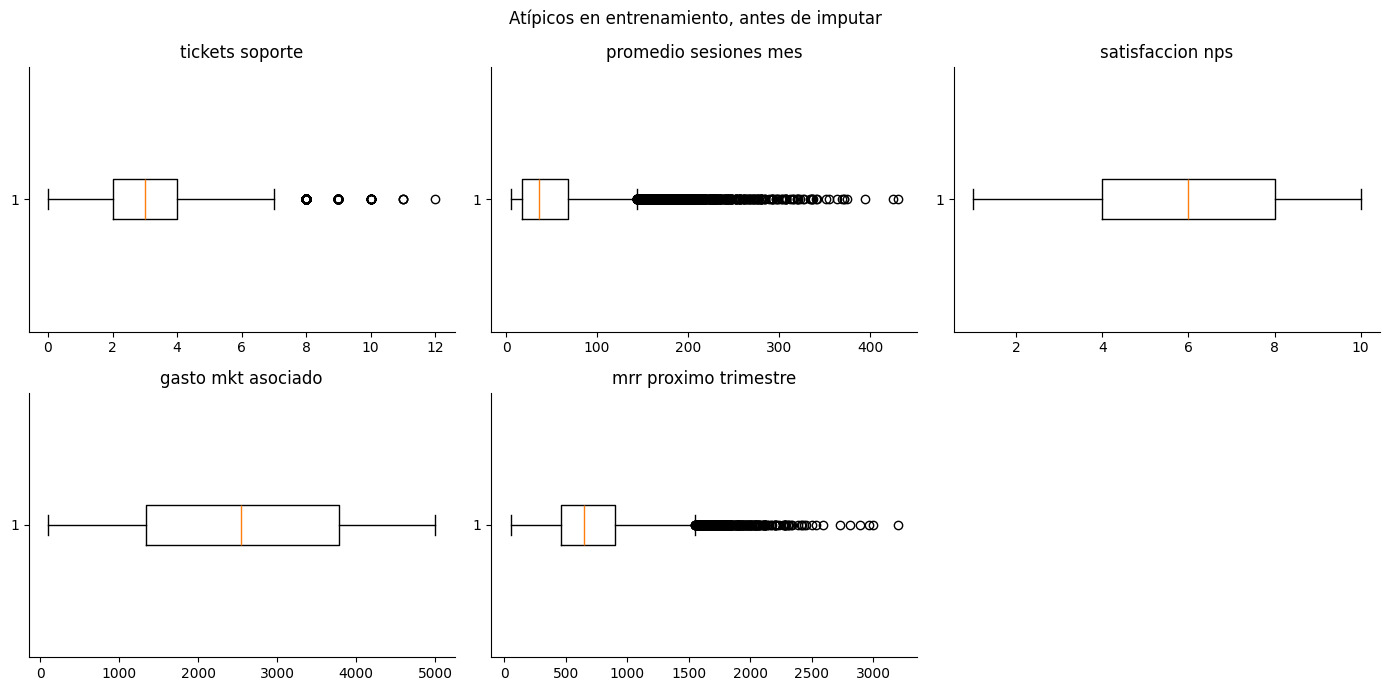

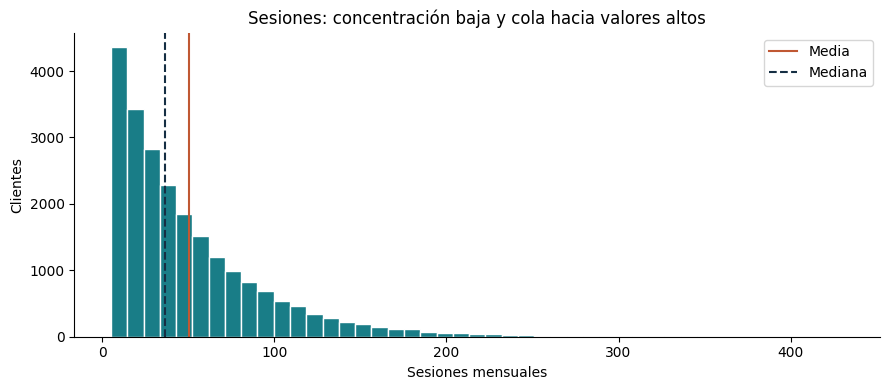

In [ ]:
X = datos.drop(columns=['id_cliente', 'mrr_proximo_trimestre']).copy()
y = datos['mrr_proximo_trimestre'].copy()
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEMILLA)
print('Entrenamiento:', len(X_train_raw), '| Prueba:', len(X_test_raw))
assert set(X_train_raw.index).isdisjoint(X_test_raw.index)

numericas_originales = ['tickets_soporte', 'promedio_sesiones_mes',
                       'satisfaccion_nps', 'gasto_mkt_asociado']
eda = X_train_raw[numericas_originales].copy()
eda['mrr_proximo_trimestre'] = y_train
resumen = eda.agg(['count', 'mean', 'median', 'std', 'min', 'max', 'skew']).T
q1, q3 = eda.quantile(0.25), eda.quantile(0.75)
iqr = q3 - q1
atipicos = (eda.lt(q1 - 1.5 * iqr) | eda.gt(q3 + 1.5 * iqr))
resumen['limite_inferior_IQR'] = q1 - 1.5 * iqr
resumen['limite_superior_IQR'] = q3 + 1.5 * iqr
resumen['atipicos_IQR'] = atipicos.sum()
resumen['porcentaje_atipicos_observados'] = atipicos.sum() / eda.count() * 100
print(resumen.round(3).to_string())

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, columna in zip(axes.flat, eda.columns):
    ax.boxplot(eda[columna].dropna(), vert=False)
    ax.set_title(columna.replace('_', ' '))
axes.flat[-1].axis('off')
fig.suptitle('Atípicos en entrenamiento, antes de imputar')
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(eda['promedio_sesiones_mes'].dropna(), bins=45, color='#197d87', edgecolor='white')
ax.axvline(eda['promedio_sesiones_mes'].mean(), color='#c05833', label='Media')
ax.axvline(eda['promedio_sesiones_mes'].median(), color='#152e43', linestyle='--', label='Mediana')
ax.set(xlabel='Sesiones mensuales', ylabel='Clientes', title='Sesiones: concentración baja y cola hacia valores altos')
ax.legend()
plt.tight_layout()
plt.show()

### Decisiones antes de imputar

**Sesiones:** la media supera la mediana y hay una cola hacia los valores altos. Se elige la **mediana** porque unos pocos clientes con mucho uso pueden subir la media. En entrenamiento, la media es 50,28 y la mediana 36,39 sesiones. La asimetría es 1,95 y 1.059 valores (4,65% de los observados) quedan fuera de los límites IQR. La tabla anterior permite comprobarlo antes de rellenar los nulos.

**Tickets y satisfacción:** se usa la **moda** de entrenamiento. Son valores discretos y así se conserva un valor habitual de la escala. Es una solución simple: no representa el valor real de cada cliente y puede concentrar demasiados registros en una sola respuesta. Se prefiere a rellenar con cero, que en satisfacción está fuera del rango.

**Atípicos:** el criterio de 1,5 IQR señala observaciones poco frecuentes, pero no demuestra que sean errores. Los rangos observados son posibles y no hay evidencia para borrar esos clientes. Se conservan todos los registros, incluso los MRR altos.

## Fase 2: Limpieza, Preprocesamiento e Ingeniería de Características


In [ ]:
def preparar_variables(base):
    preparado = base.copy()
    fecha = pd.to_datetime(preparado.pop('fecha_registro'), errors='coerce')
    preparado['antiguedad_dias'] = (FECHA_CORTE - fecha).dt.total_seconds() / 86400
    preparado['duracion_contrato'] = preparado['duracion_contrato'].map(
        {'Mensual': 1, 'Anual': 12, '2 Años': 24})
    preparado['pago_puntual'] = preparado['pago_puntual'].map({'No': 0, 'Si': 1})
    return preparado

X_train = preparar_variables(X_train_raw)
X_test = preparar_variables(X_test_raw)
continuas = ['promedio_sesiones_mes', 'gasto_mkt_asociado', 'antiguedad_dias']
discretas = ['tickets_soporte', 'satisfaccion_nps']
mapeadas = ['duracion_contrato', 'pago_puntual']

preprocesador = ColumnTransformer([
    ('continuas', Pipeline([
        ('imputar', SimpleImputer(strategy='median')),
        ('escalar', RobustScaler())
    ]), continuas),
    ('discretas', SimpleImputer(strategy='most_frequent'), discretas),
    ('tamano', Pipeline([
        ('imputar', SimpleImputer(strategy='most_frequent')),
        ('codificar', OrdinalEncoder(categories=[['Pequeña', 'Mediana', 'Grande']]))
    ]), ['tamano_empresa']),
    ('sector', Pipeline([
        ('imputar', SimpleImputer(strategy='most_frequent')),
        ('codificar', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
    ]), ['sector_empresa']),
    ('mapeadas', SimpleImputer(strategy='most_frequent'), mapeadas)
])
modelo = Pipeline([
    ('preprocesar', preprocesador),
    ('regresion', LinearRegression())
])
print(X_train.head().to_string(index=False))

sector_empresa tamano_empresa  tickets_soporte  promedio_sesiones_mes  satisfaccion_nps  duracion_contrato  gasto_mkt_asociado  pago_puntual  antiguedad_dias
    Tecnologia        Mediana              4.0                    NaN               8.0                  1         4959.807524             1       926.123337
    Tecnologia        Pequeña              1.0              30.256762               6.0                 12         3536.074990             1      1212.901230
      Finanzas        Mediana              3.0             127.906214              10.0                  1         4281.647555             1      1527.237541
      Finanzas        Pequeña              6.0              80.356272               2.0                  1          567.040382             1      1766.746358
        Retail         Grande              5.0              48.703764               7.0                  1         2688.016301             1       321.176506


## 3. Entrenamiento de la regresión lineal

`fit` aprende los valores para rellenar nulos, las escalas y la regresión con los 24.000 clientes de entrenamiento. Al predecir en prueba solo se reutilizan esos valores. El ID se excluye porque identifica al cliente y no describe su comportamiento.

La escala robusta resta la mediana y divide por el rango intercuartílico. Ayuda a expresar las variables continuas en magnitudes comparables. En una regresión lineal sin regularización, un cambio lineal de escala no mejora por sí solo las predicciones.

In [ ]:
modelo.fit(X_train, y_train)
prep = modelo.named_steps['preprocesar']
print('Medianas de imputación:')
print(pd.Series(prep.named_transformers_['continuas'].named_steps['imputar'].statistics_,
                index=continuas).round(4).to_string())
print('\nModas de imputación:')
print(pd.Series(prep.named_transformers_['discretas'].statistics_, index=discretas).to_string())
print('\nEscalas (IQR):')
print(pd.Series(prep.named_transformers_['continuas'].named_steps['escalar'].scale_,
                index=continuas).round(4).to_string())
print('\nSector de referencia:', prep.named_transformers_['sector'].named_steps['codificar'].categories_[0][0])
assert np.isfinite(prep.transform(X_train)).all()
assert np.isfinite(prep.transform(X_test)).all()

Medianas de imputación:
promedio_sesiones_mes      36.3950
gasto_mkt_asociado       2538.6054
antiguedad_dias           911.7966

Modas de imputación:
tickets_soporte     3.0
satisfaccion_nps    7.0

Escalas (IQR):
promedio_sesiones_mes      46.7361
gasto_mkt_asociado       2449.4131
antiguedad_dias           911.7091

Sector de referencia: Educacion


## 4. Evaluación en clientes de prueba

Se calcula R² y MAE con clientes que el modelo no vio al entrenar. Como comparación simple, se incluye un modelo que asigna a todos la mediana del MRR de entrenamiento. La mediana es una referencia adecuada para evaluar error absoluto.

In [ ]:
y_pred = modelo.predict(X_test)
y_pred_train = modelo.predict(X_train)
base = DummyRegressor(strategy='median').fit(X_train, y_train)
y_base = base.predict(X_test)
metricas = pd.DataFrame({
    'Conjunto / modelo': ['Entrenamiento / lineal', 'Prueba / lineal', 'Prueba / mediana fija'],
    'R2': [r2_score(y_train, y_pred_train), r2_score(y_test, y_pred), r2_score(y_test, y_base)],
    'MAE_USD': [mean_absolute_error(y_train, y_pred_train),
                mean_absolute_error(y_test, y_pred), mean_absolute_error(y_test, y_base)]
})
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mae_base = mean_absolute_error(y_test, y_base)
reduccion_mae = (1 - mae / mae_base) * 100
print(metricas.round(4).to_string(index=False))
print(f'\nReducción de MAE frente a la mediana fija: {reduccion_mae:.2f}%')
print('Predicciones negativas:', int((y_pred < 0).sum()))
print(f'El modelo explica aproximadamente el {r2*100:.2f}% de la variación del MRR en prueba.')
print(f'La predicción se desvía, en promedio, {mae:.2f} USD del MRR mensual real por cliente.')

     Conjunto / modelo      R2  MAE_USD
Entrenamiento / lineal  0.9203  69.1250
       Prueba / lineal  0.9175  70.6608
 Prueba / mediana fija -0.0357 259.1351

Reducción de MAE frente a la mediana fija: 72.73%
Predicciones negativas: 4
El modelo explica aproximadamente el 91.75% de la variación del MRR en prueba.
La predicción se desvía, en promedio, 70.66 USD del MRR mensual real por cliente.


id_cliente  mrr_proximo_trimestre  prediccion_USD  residuo_USD  error_absoluto_USD  tenia_nulos
 CLI-28225                 668.25          536.82       131.43              131.43         True
 CLI-18704                 479.26          517.04       -37.78               37.78        False
  CLI-0553                 840.35          887.11       -46.76               46.76        False
  CLI-3784                 637.62          589.97        47.65               47.65        False
  CLI-4410                 433.85          536.62      -102.77              102.77        False
 CLI-17107                 705.34          773.48       -68.14               68.14        False
 CLI-14314                 707.61          575.23       132.38              132.38        False
 CLI-10803                 765.44          707.37        58.07               58.07        False
  CLI-6129                 821.71          876.39       -54.68               54.68        False
  CLI-5923                1444.45       

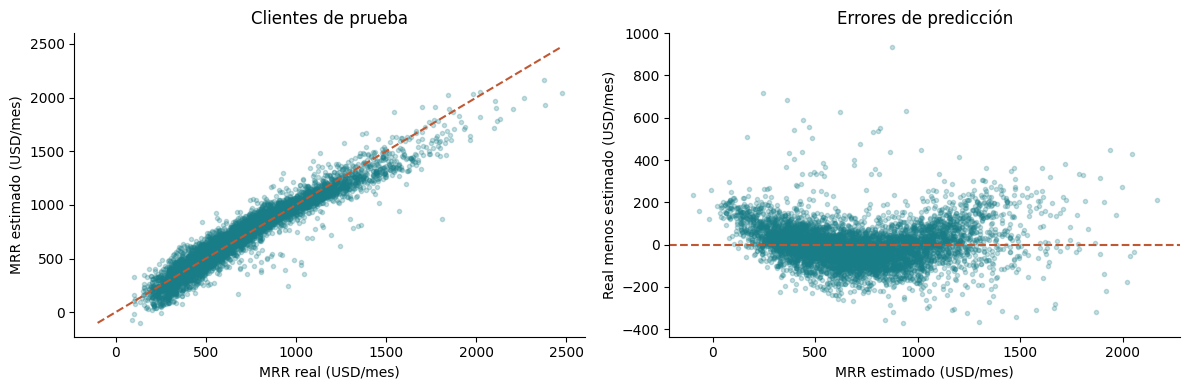

In [ ]:
resultados = datos.loc[X_test.index, ['id_cliente', 'mrr_proximo_trimestre']].copy()
resultados['prediccion_USD'] = y_pred
resultados['residuo_USD'] = y_test - y_pred
resultados['error_absoluto_USD'] = abs(y_test - y_pred)
resultados['tenia_nulos'] = X_test_raw.isna().any(axis=1)
print(resultados.head(10).round(2).to_string(index=False))
print('\nError según disponibilidad de datos:')
print(resultados.groupby('tenia_nulos').agg(clientes=('id_cliente', 'size'),
    MAE_USD=('error_absoluto_USD', 'mean')).round(2).to_string())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(y_test, y_pred, s=9, alpha=.25, color='#197d87')
limites = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax[0].plot(limites, limites, '--', color='#c05833')
ax[0].set(xlabel='MRR real (USD/mes)', ylabel='MRR estimado (USD/mes)', title='Clientes de prueba')
ax[1].scatter(y_pred, y_test-y_pred, s=9, alpha=.25, color='#197d87')
ax[1].axhline(0, color='#c05833', linestyle='--')
ax[1].set(xlabel='MRR estimado (USD/mes)', ylabel='Real menos estimado (USD/mes)', title='Errores de predicción')
plt.tight_layout()
plt.show()

### Variables que más aportan a la predicción

Para comparar variables de distinta escala se desordena una columna de prueba a la vez y se mide cuánto aumenta el MAE. Si el error aumenta mucho, el modelo dependía de esa información. Se repite cinco veces para reducir el efecto del orden aleatorio. Este análisis se usa después de fijar el modelo, solo para interpretarlo, sin seleccionar variables ni volver a entrenar con los resultados de prueba.

             variable  aumento_MAE_USD  desviacion_repeticiones
       tamano_empresa          201.045                    1.802
promedio_sesiones_mes          119.616                    1.595
    duracion_contrato           47.544                    0.657
         pago_puntual           41.933                    0.619
     satisfaccion_nps           19.710                    0.512
   gasto_mkt_asociado            9.961                    0.268
      tickets_soporte            8.092                    0.389
      antiguedad_dias            0.001                    0.002
       sector_empresa            0.000                    0.005

Coeficientes en unidades originales:
continuas__promedio_sesiones_mes       4.0092
continuas__gasto_mkt_asociado          0.0232
continuas__antiguedad_dias             0.0004
discretas__tickets_soporte           -17.5544
discretas__satisfaccion_nps           22.1899
tamano__tamano_empresa               324.1582
sector__sector_empresa_Finanzas        1.7183


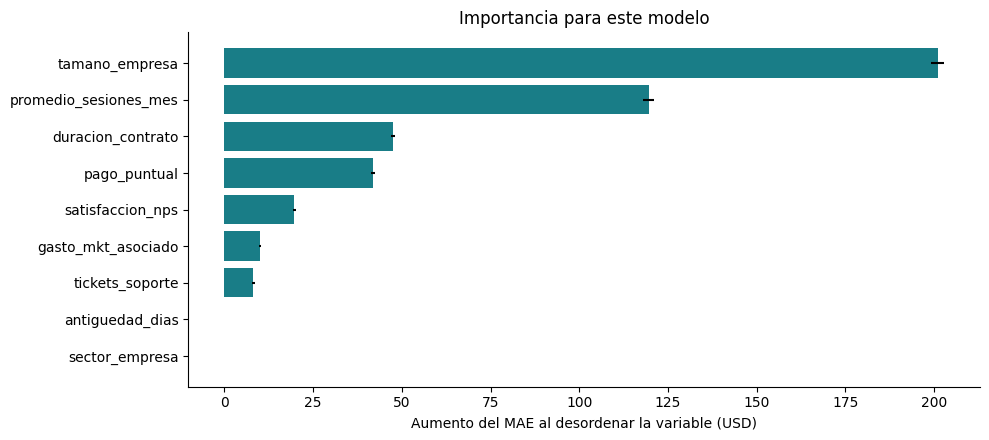

In [ ]:
permutacion = permutation_importance(modelo, X_test, y_test,
    scoring='neg_mean_absolute_error', n_repeats=5, random_state=SEMILLA, n_jobs=1)
importancia = pd.DataFrame({'variable': X_test.columns,
    'aumento_MAE_USD': permutacion.importances_mean,
    'desviacion_repeticiones': permutacion.importances_std}).sort_values('aumento_MAE_USD', ascending=False)
print(importancia.round(3).to_string(index=False))
coeficientes = pd.Series(modelo.named_steps['regresion'].coef_,
    index=prep.get_feature_names_out(), name='USD_por_unidad')
escalas = prep.named_transformers_['continuas'].named_steps['escalar'].scale_
for columna, escala in zip(continuas, escalas):
    coeficientes.loc['continuas__' + columna] /= escala
print('\nCoeficientes en unidades originales:')
print(coeficientes.round(4).to_string())
fig, ax = plt.subplots(figsize=(10, 4.5))
orden = importancia.iloc[::-1]
ax.barh(orden['variable'], orden['aumento_MAE_USD'], color='#197d87',
        xerr=orden['desviacion_repeticiones'])
ax.set(xlabel='Aumento del MAE al desordenar la variable (USD)', title='Importancia para este modelo')
plt.tight_layout()
plt.show()

## Resultados y conclusión

En los **6.000 clientes de prueba**, el modelo obtuvo **R² = 0.9175** y **MAE = 70.66 USD**. Esto significa que explica aproximadamente el **91.75% de la variación del MRR** y que la predicción se desvía, en promedio, **70.66 dólares mensuales por cliente**.

La referencia de asignar la misma mediana a todos obtuvo un MAE de **259.14 USD**. La regresión reduce ese error un **72.73%**, por lo que aporta información frente a una estimación igual para todos.

Las variables con mayor importancia por permutación son **tamano_empresa, promedio_sesiones_mes, duracion_contrato**. El tamaño se asocia con unos **324.16 USD** adicionales por nivel y una sesión mensual adicional con **4.01 USD**, manteniendo lo demás constante. Estos valores describen el ajuste, no el efecto garantizado de una acción comercial.

El modelo puede ayudar a estimar ingresos, pero conviene usarlo como apoyo. Para decidir si un cliente está perdiendo ingresos falta conocer su MRR actual. Tampoco se puede prometer un ahorro o ROI con esta base. El siguiente paso sería probarlo en un trimestre posterior y medir si mejora las decisiones de atención.

El MAE es 64,18 USD en los clientes de prueba sin nulos y 91,11 USD en quienes tienen al menos un dato faltante. Esto respalda mejorar la captura de datos. Se obtuvieron **4 predicciones negativas**: se mantienen para reportar las métricas originales, pero requieren revisión porque un MRR negativo no tiene sentido aquí. La regresión lineal no limita automáticamente sus predicciones a valores positivos.
